# 1. The data: one text, two chronologies

This notebook introduces the materials. Nothing is predicted yet. The goal is to understand what we are working with *before* any model touches it, because every later result depends on choices made here.

You do not need to read Arabic. Every verse also comes with an English translation, and the code prints transliterations where it can.

**Run each cell in order** (Shift+Enter). If a cell fails, read the error before re-running.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from surahs import load_surahs, load_verses, load_surah_texts
from surahs.plotting import PERIOD_STYLE, style_axes

pd.set_option("display.max_colwidth", 120)

## 1.1 The surah table

The Qur'an has 114 chapters, called *surahs*. Each row below is one surah. Two columns come from the **1924 Cairo edition** of the Qur'an, the standard printed text used worldwide today:

- `cairo_place`: whether the edition calls the surah "Meccan" (revealed before the Prophet's emigration to Medina in 622 CE) or "Medinan" (after it);
- `cairo_order`: the edition's chronological rank, 1 = earliest.

These come from Islamic tradition: reports about the occasions of revelation and early lists attributed to figures like Ibn ʿAbbās.

Three columns come from **Theodor Nöldeke**, a German scholar whose *Geschichte des Qorāns* (1860; revised with Friedrich Schwally, 1909–1938) has been the reference point for Western dating ever since:

- `noldeke_order`: his chronological rank;
- `noldeke_period`: his four periods, "Meccan I", "Meccan II", "Meccan III" and "Medinan";
- `noldeke_place`: the same thing collapsed to Meccan/Medinan.

In [2]:
surahs = load_surahs()
surahs.head(10)

,name_ar,name_translit,name_en,n_verses,cairo_order,cairo_place,noldeke_order,noldeke_period,noldeke_place,labels_disagree,sinai_mvl_rank,dost_phase,dost_note
surah,,,,,,,,,,,,,
1,الفاتحة,Al-Faatiha,The Opening,7,5,Meccan,48,Meccan I,Meccan,False,30,unassigned,not assigned; Dost thinks 112 and 1 are likely later than their MVL suggests
2,البقرة,Al-Baqara,The Cow,286,87,Medinan,91,Medinan,Medinan,False,108,A,"A-Qur'an, but opening section likely from AR period (composite)"
3,آل عمران,Aal-i-Imraan,The Family of Imraan,200,89,Medinan,97,Medinan,Medinan,False,97,A,"A-Qur'an, but opening section likely from AR period (composite)"
4,النساء,An-Nisaa,The Women,176,92,Medinan,100,Medinan,Medinan,False,110,A,
5,المائدة,Al-Maaida,The Table,120,112,Medinan,114,Medinan,Medinan,False,112,A,
6,الأنعام,Al-An'aam,The Cattle,165,55,Meccan,89,Meccan III,Meccan,False,99,AR,AR-Qur'an despite long verses: Allāh-per-verse below 1
7,الأعراف,Al-A'raaf,The Heights,206,39,Meccan,87,Meccan III,Meccan,False,90,AR,"AR-Qur'an, with an A-Qur'an section (vv. 156-162)"
8,الأنفال,Al-Anfaal,The Spoils of War,75,88,Medinan,95,Medinan,Medinan,False,94,A,
9,التوبة,At-Tawba,The Repentance,129,113,Medinan,113,Medinan,Medinan,False,104,A,


In [3]:
surahs.noldeke_period.value_counts().sort_index()

noldeke_period
Meccan I      48
Meccan II     21
Meccan III    21
Medinan       24
Name: count, dtype: int64

In [4]:
pd.crosstab(surahs.cairo_place, surahs.noldeke_place, margins=True)

noldeke_place,Meccan,Medinan,All
cairo_place,,,
Meccan,86,0,86
Medinan,4,24,28
All,90,24,114


The two systems agree on 110 of 114 surahs. Here are the four where they don't:

In [5]:
surahs[surahs.labels_disagree][["name_translit", "name_en", "n_verses", "cairo_place", "noldeke_period"]]

,name_translit,name_en,n_verses,cairo_place,noldeke_period
surah,,,,,
13,Ar-Ra'd,The Thunder,43,Medinan,Meccan III
55,Ar-Rahmaan,The Beneficent,78,Medinan,Meccan I
76,Al-Insaan,Man,31,Medinan,Meccan II
99,Az-Zalzala,The Earthquake,8,Medinan,Meccan I


Keep these four in mind: **13, 55, 76 and 99**. Labels are not facts handed down from the sky. They are scholarly claims, and here two respected traditions make different claims. Any model we train on one set of labels will inherit that set's choices.

**Question 1.1.** Look up surah 55 (al-Raḥmān) in English (e.g. at https://quran.com/55). Why might someone think it was early? Why might someone think it was Medinan? Write two or three sentences.

## 1.2 The verse table

Each surah is made of verses (*āyāt*, singular *āya*). The standard Kufan numbering has 6,236 verses. For each one we have:

- `text`: the Arabic, without vowel marks (from the Tanzil Project);
- `english`: Marmaduke Pickthall's 1930 translation;
- `lemmas`: the dictionary form of every word *and* every attached particle (from the Quranic Arabic Corpus). Arabic glues "and", "the", "to" and pronouns onto words, so وقالوا ("and they said") becomes three lemmas: و (and) + قال (say) + the plural pronoun;
- `roots`: the three-letter consonantal roots that carry the core meaning, e.g. k-f-r ("disbelief") underlies *kafara*, *kāfir*, *kufr*;
- `n_words`, `n_letters`: verse length.

In [6]:
verses = load_verses()
print(len(verses), "verses")
verses[["ref", "text", "english", "n_words", "n_letters", "cairo_place", "noldeke_period"]].sample(6, random_state=1)

6236 verses


,ref,text,english,n_words,n_letters,cairo_place,noldeke_period
6111,96:6,كلا إن الإنسان ليطغى,"Nay, but verily man is rebellious",4,17,Meccan,Meccan I
1669,12:74,قالوا فما جزاؤه إن كنتم كاذبين,"They said: And what shall be the penalty for it, if ye prove liars?",6,25,Meccan,Meccan III
2394,20:47,فأتياه فقولا إنا رسولا ربك فأرسل معنا بني إسرائيل ولا تعذبهم قد جئناك بآية من ربك والسلام على من اتبع الهدى,"So go ye unto him and say: Lo! we are two messengers of thy Lord. So let the children of Israel go with us, and torm...",21,87,Meccan,Meccan II
383,3:91,إن الذين كفروا وماتوا وهم كفار فلن يقبل من أحدهم ملء الأرض ذهبا ولو افتدى به أولئك لهم عذاب أليم وما لهم من ناصرين,"Lo! those who disbelieve, and die in disbelief, the (whole) earth full of gold would not be accepted from such an on...",24,91,Medinan,Medinan
2253,19:4,قال رب إني وهن العظم مني واشتعل الرأس شيبا ولم أكن بدعائك رب شقيا,"Saying: My Lord! Lo! the bones of me wax feeble and my head is shining with grey hair, and I have never been unblest...",14,52,Meccan,Meccan II
6148,100:3,فالمغيرات صبحا,"And scouring to the raid at dawn,",2,13,Meccan,Meccan I


### A data-cleaning decision you should know about

In the printed Qur'an, every surah except the 9th opens with the *basmala*, "In the name of God, the Merciful, the Compassionate." In the standard count it is a numbered verse only in surah 1. Tanzil's plain-text download nonetheless glues it onto verse 1 of every other surah. The 2017 version of this project left it there, so the same four words were counted 112 extra times. We strip it out:

In [7]:
verses.set_index("ref").loc[["1:1", "2:1", "96:1"], ["text", "english"]]

,text,english
ref,,
1:1,بسم الله الرحمن الرحيم,"In the name of Allah, the Beneficent, the Merciful."
2:1,الم,Alif. Lam. Mim.
96:1,اقرأ باسم ربك الذي خلق,"Read: In the name of thy Lord Who createth,"


## 1.3 A first look: verse length

Readers have long noticed that the surahs the tradition calls Medinan tend to be long, with long verses. The surahs it calls early Meccan are short, with short, rhyming verses. Let's check.

In [8]:
verses.groupby("noldeke_period", observed=True)[["n_words", "n_letters"]].median()

,n_words,n_letters
noldeke_period,,
Meccan I,4.0,17.0
Meccan II,8.0,34.0
Meccan III,15.0,61.5
Medinan,17.0,73.0


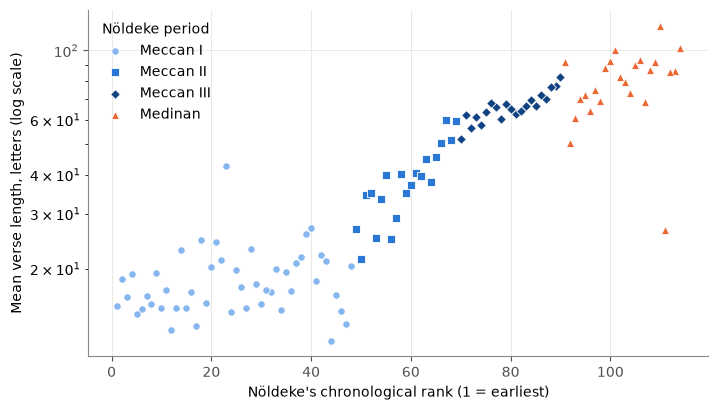

In [9]:
s = load_surah_texts()
fig, ax = plt.subplots(figsize=(8, 4.5))
for period, st in PERIOD_STYLE.items():
    g = s[s.noldeke_period == period]
    ax.scatter(g.noldeke_order, g.mvl, label=period, **st)
ax.set_yscale("log")
ax.set_xlabel("Nöldeke's chronological rank (1 = earliest)")
ax.set_ylabel("Mean verse length, letters (log scale)")
style_axes(ax); ax.legend(frameon=False, title="Nöldeke period");

That is a strong pattern: mean verse length (MVL) rises steadily through Nöldeke's sequence.

**But be careful about what this shows.** Nöldeke *used* verse length and style, among other things, to build his order. So the fact that his order lines up with verse length is partly circular: we are getting back something he put in. Sadeghi (2011) and Sinai (2017) argue that the pattern is nevertheless real, because *other*, independent features line up the same way. Notebook 3 tests that argument.

**Question 1.2.** If you wanted to test whether verse length really tracks time, what kind of evidence *independent* of Nöldeke would you want? (Hint: think about the four disputed surahs, or about features Nöldeke didn't look at.)

## 1.4 Explore

Change the surah number and read a few verses in both languages. Try an early surah (96, 74, 81), a middle one (19, 20, 36) and a Medinan one (2, 4, 9).

In [10]:
SURAH = 81
verses[verses.surah == SURAH][["ref", "text", "english", "n_letters"]].head(15)

,ref,text,english,n_letters
5800,81:1,إذا الشمس كورت,"When the sun is overthrown,",12
5801,81:2,وإذا النجوم انكدرت,"And when the stars fall,",16
5802,81:3,وإذا الجبال سيرت,"And when the hills are moved,",14
5803,81:4,وإذا العشار عطلت,"And when the camels big with young are abandoned,",14
5804,81:5,وإذا الوحوش حشرت,"And when the wild beasts are herded together,",14
5805,81:6,وإذا البحار سجرت,"And when the seas rise,",14
5806,81:7,وإذا النفوس زوجت,"And when souls are reunited,",14
5807,81:8,وإذا الموءودة سئلت,And when the girl-child that was buried alive is asked,16
5808,81:9,بأي ذنب قتلت,"For what sin she was slain,",10
5809,81:10,وإذا الصحف نشرت,"And when the pages are laid open,",13
